In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

In [2]:
df = pd.read_csv("sales_data_sample.csv", encoding="latin1")

print("First five rows:")
display(df.head())

print("\nDataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

First five rows:


,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium



Dataset shape: (2823, 25)

Column names:
['ORDERNUMBER', 'QUANTITYORDERED', 'PRICEEACH', 'ORDERLINENUMBER', 'SALES', 'ORDERDATE', 'STATUS', 'QTR_ID', 'MONTH_ID', 'YEAR_ID', 'PRODUCTLINE', 'MSRP', 'PRODUCTCODE', 'CUSTOMERNAME', 'PHONE', 'ADDRESSLINE1', 'ADDRESSLINE2', 'CITY', 'STATE', 'POSTALCODE', 'COUNTRY', 'TERRITORY', 'CONTACTLASTNAME', 'CONTACTFIRSTNAME', 'DEALSIZE']

Missing values:
ORDERNUMBER            0
QUANTITYORDERED        0
PRICEEACH              0
ORDERLINENUMBER        0
SALES                  0
ORDERDATE              0
STATUS                 0
QTR_ID                 0
MONTH_ID               0
YEAR_ID                0
PRODUCTLINE            0
MSRP                   0
PRODUCTCODE            0
CUSTOMERNAME           0
PHONE                  0
ADDRESSLINE1           0
ADDRESSLINE2        2521
CITY                   0
STATE               1486
POSTALCODE            76
COUNTRY                0
TERRITORY           1074
CONTACTLASTNAME        0
CONTACTFIRSTNAME       0
DEALSIZE

In [3]:
candidate_features = [
    "QUANTITYORDERED",
    "PRICEEACH",
    "SALES",
    "MSRP"
]

features = [col for col in candidate_features if col in df.columns]

print("Selected features:", features)

X = df[features].copy()

print("\nSelected data:")
display(X.head())

print("\nMissing values in selected features:")
print(X.isnull().sum())

Selected features: ['QUANTITYORDERED', 'PRICEEACH', 'SALES', 'MSRP']

Selected data:


,QUANTITYORDERED,PRICEEACH,SALES,MSRP
0,30,95.70,2871.00,95
1,34,81.35,2765.90,95
2,41,94.74,3884.34,95
3,45,83.26,3746.70,95
4,49,100.00,5205.27,95



Missing values in selected features:
QUANTITYORDERED    0
PRICEEACH          0
SALES              0
MSRP               0
dtype: int64


In [4]:
X = X.dropna()

print("Shape after removing missing values:", X.shape)

Shape after removing missing values: (2823, 4)


In [5]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Feature scaling completed.")
print("Scaled data shape:", X_scaled.shape)

Feature scaling completed.
Scaled data shape: (2823, 4)


In [6]:
wcss = []

for k in range(1, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)
    wcss.append(model.inertia_)

print("WCSS values:")
print(wcss)

WCSS values:
[11292.0, 6741.690574808543, 4766.014280081643, 3934.894121194952, 3348.268527079659, 2858.818306188108, 2548.5359725153376, 2350.6600480147936, 2169.967218236506, 2019.7529981769583]


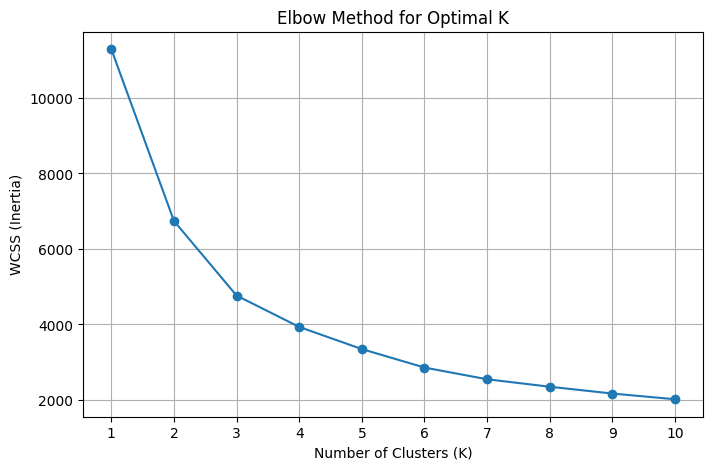

In [7]:
plt.figure(figsize=(8, 5))

plt.plot(range(1, 11), wcss, marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS (Inertia)")
plt.title("Elbow Method for Optimal K")
plt.xticks(range(1, 11))
plt.grid(True)

plt.show()

In [8]:
k = 3

kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_scaled)

print("K-Means clustering completed.")
print("\nCluster distribution:")
print(pd.Series(kmeans_labels).value_counts().sort_index())

K-Means clustering completed.

Cluster distribution:
0    975
1    852
2    996
Name: count, dtype: int64


In [9]:
kmeans_results = X.copy()
kmeans_results["KMeans_Cluster"] = kmeans_labels

display(kmeans_results.head(10))

,QUANTITYORDERED,PRICEEACH,SALES,MSRP,KMeans_Cluster
0,30,95.70,2871.00,95,2
1,34,81.35,2765.90,95,2
2,41,94.74,3884.34,95,1
3,45,83.26,3746.70,95,1
4,49,100.00,5205.27,95,1
5,36,96.66,3479.76,95,2
6,29,86.13,2497.77,95,2
7,48,100.00,5512.32,95,1
8,22,98.57,2168.54,95,2
9,41,100.00,4708.44,95,1


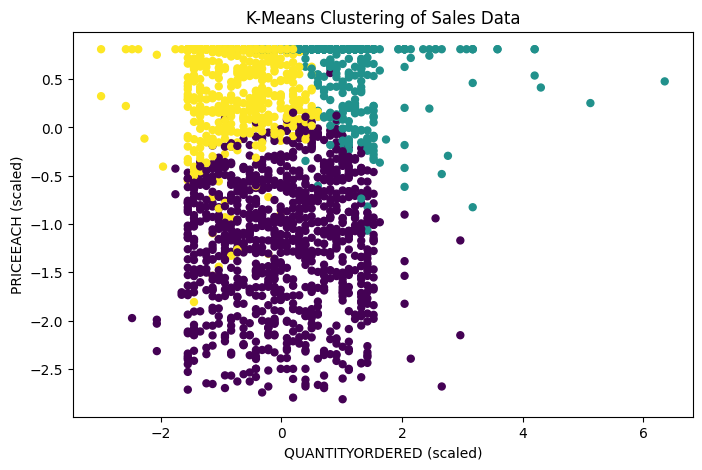

In [10]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=kmeans_labels,
    cmap="viridis",
    s=25
)

plt.xlabel(features[0] + " (scaled)")
plt.ylabel(features[1] + " (scaled)")
plt.title("K-Means Clustering of Sales Data")
plt.show()

In [11]:
hierarchical = AgglomerativeClustering(
    n_clusters=k,
    linkage="ward"
)

hierarchical_labels = hierarchical.fit_predict(X_scaled)

print("Hierarchical clustering completed.")
print("\nCluster distribution:")
print(
    pd.Series(hierarchical_labels)
    .value_counts()
    .sort_index()
)

Hierarchical clustering completed.

Cluster distribution:
0    1204
1     934
2     685
Name: count, dtype: int64


In [12]:
hierarchical_results = X.copy()
hierarchical_results["Hierarchical_Cluster"] = hierarchical_labels

display(hierarchical_results.head(10))

,QUANTITYORDERED,PRICEEACH,SALES,MSRP,Hierarchical_Cluster
0,30,95.70,2871.00,95,2
1,34,81.35,2765.90,95,2
2,41,94.74,3884.34,95,0
3,45,83.26,3746.70,95,0
4,49,100.00,5205.27,95,1
5,36,96.66,3479.76,95,0
6,29,86.13,2497.77,95,2
7,48,100.00,5512.32,95,1
8,22,98.57,2168.54,95,2
9,41,100.00,4708.44,95,1


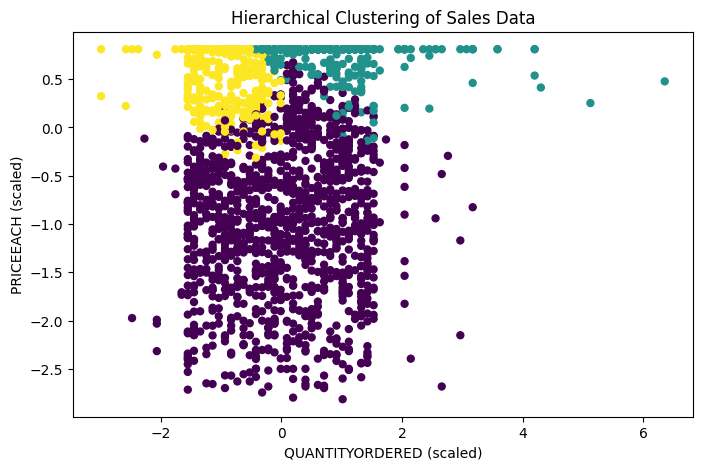

In [13]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=hierarchical_labels,
    cmap="viridis",
    s=25
)

plt.xlabel(features[0] + " (scaled)")
plt.ylabel(features[1] + " (scaled)")
plt.title("Hierarchical Clustering of Sales Data")
plt.show()

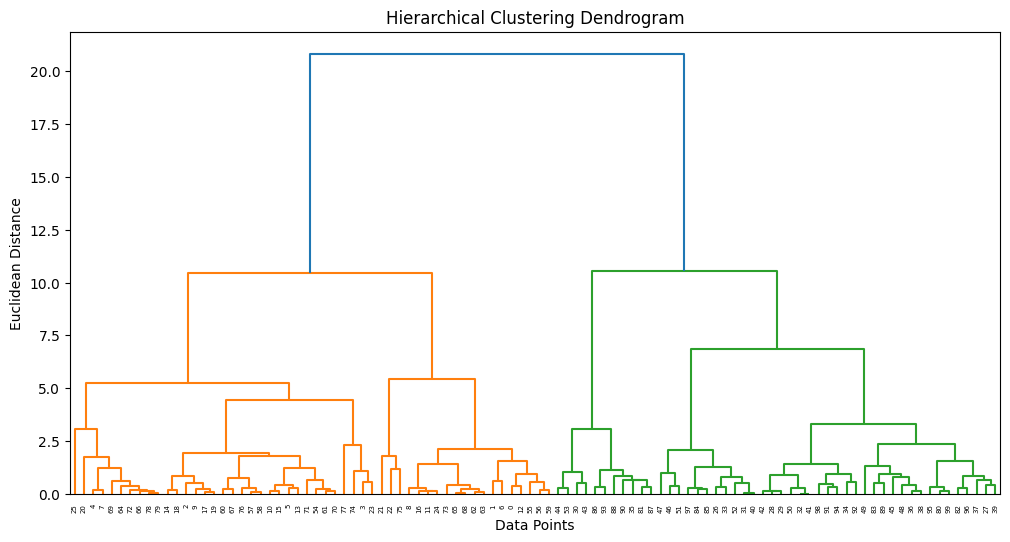

In [14]:
sample_size = min(100, len(X_scaled))

sample_data = X_scaled[:sample_size]

linked = linkage(sample_data, method="ward")

plt.figure(figsize=(12, 6))

dendrogram(linked)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Euclidean Distance")
plt.show()

In [15]:
comparison = pd.DataFrame({
    "K-Means Cluster": kmeans_labels,
    "Hierarchical Cluster": hierarchical_labels
})

print("Comparison of cluster assignments:")
display(comparison.head(10))

print("\nK-Means cluster sizes:")
print(comparison["K-Means Cluster"].value_counts().sort_index())

print("\nHierarchical cluster sizes:")
print(
    comparison["Hierarchical Cluster"]
    .value_counts()
    .sort_index()
)

Comparison of cluster assignments:


,K-Means Cluster,Hierarchical Cluster
0,2,2
1,2,2
2,1,0
3,1,0
4,1,1
5,2,0
6,2,2
7,1,1
8,2,2
9,1,1



K-Means cluster sizes:
K-Means Cluster
0    975
1    852
2    996
Name: count, dtype: int64

Hierarchical cluster sizes:
Hierarchical Cluster
0    1204
1     934
2     685
Name: count, dtype: int64
